# DBSCAN – Density-Based Spatial Clustering of Applications with Noise

## DBSCAN Hyperparameters in Scikit-Learn

In [2]:
from sklearn.cluster import DBSCAN

model = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="euclidean",
    algorithm="auto",
    leaf_size=30,
    p=2,
    n_jobs=-1
)


### Step 1: Import Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.neighbors import NearestNeighbors

### Step 2: Create a Synthetic Dataset (with Outliers)

In [4]:
X, y = make_blobs(
    n_samples=5000,
    centers=4,
    n_features=5,
    cluster_std=1.2,
    random_state=42
)

df = pd.read_excel('dbscan_dataset.xlsx')

print(df.head())
print(df.shape)
print(df.describe())

   Annual_Income  Spending_Score  Purchases  Website_Visits  \
0   10000.000000           100.0  52.974392       20.100125   
1   10000.000000           100.0  60.145085        0.000000   
2   34931.745907           100.0  35.129307       18.759640   
3   10000.000000             0.0  60.330777       20.068879   
4   10000.000000           100.0  49.368815        0.000000   

   Days_Since_Last_Purchase  
0                  0.000000  
1                  0.000000  
2                  0.000000  
3                106.583826  
4                  0.000000  
(5030, 5)
       Annual_Income  Spending_Score    Purchases  Website_Visits  \
count    5030.000000     5030.000000  5030.000000     5030.000000   
mean    17715.921625       52.720291    43.535402       13.887379   
std     20156.197279       47.461708    14.956540       10.581963   
min     10000.000000        0.000000     0.142743        0.000000   
25%     10000.000000        0.000000    31.990925        0.911855   
50%     10000.000

In [5]:
df

,Annual_Income,Spending_Score,Purchases,Website_Visits,Days_Since_Last_Purchase
0,10000.000000,100.000000,52.974392,20.100125,0.000000
1,10000.000000,100.000000,60.145085,0.000000,0.000000
2,34931.745907,100.000000,35.129307,18.759640,0.000000
3,10000.000000,0.000000,60.330777,20.068879,106.583826
4,10000.000000,100.000000,49.368815,0.000000,0.000000
...,...,...,...,...,...
5025,214141.871468,1.601362,1.337314,1.080663,327.628392
5026,230895.645140,0.840331,4.665382,1.688641,347.743847
5027,216138.356347,5.243734,2.649321,0.649388,327.248083
5028,214324.627803,9.329371,2.245164,2.354211,351.477319


### Step 3 & Step 4: Missing Value Imputation & Feature Scaling

In [6]:
print(df.isnull().sum())

imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(df)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print(X_scaled[:5])

Annual_Income               0
Spending_Score              0
Purchases                   0
Website_Visits              0
Days_Since_Last_Purchase    0
dtype: int64
[[-0.38284447  0.99626439  0.63115726  0.58716544 -0.50828232]
 [-0.38284447  0.99626439  1.11064018 -1.31249367 -0.50828232]
 [ 0.85420556  0.99626439 -0.56209059  0.46047648 -0.50828232]
 [-0.38284447 -1.11090675  1.12305683  0.58421238  2.19854416]
 [-0.38284447  0.99626439  0.39006301 -1.31249367 -0.50828232]]


## 17. K-Distance Graph to Estimate Epsilon

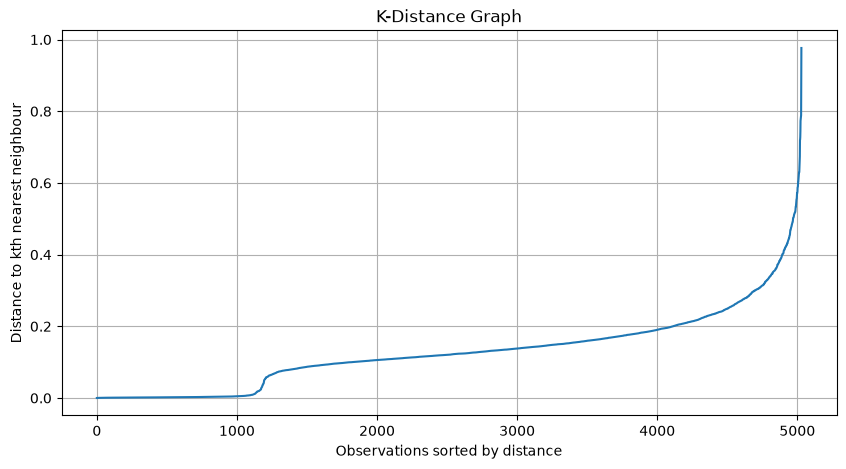

In [7]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 5

neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES,
    metric="euclidean"
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Distance to the kth nearest neighbour
k_distances = distances[:, -1]

# Sort distances
k_distances_sorted = np.sort(k_distances)

plt.figure(figsize=(10, 5))

plt.plot(k_distances_sorted)

plt.xlabel("Observations sorted by distance")
plt.ylabel("Distance to kth nearest neighbour")
plt.title("K-Distance Graph")

plt.grid(True)

plt.show()

## 18. Train DBSCAN & 19. Check Cluster Distribution

In [8]:
model = DBSCAN(
    eps=0.8,
    min_samples=5,
    metric="euclidean",
    algorithm="auto",
    n_jobs=-1
)

labels = model.fit_predict(X_scaled)

df["Cluster"] = labels

print(df.head())

cluster_counts = df["Cluster"].value_counts().sort_index()

print(cluster_counts)

print("Number of clusters:")

number_of_clusters = len(
    set(labels) - {-1}
)

print(number_of_clusters)

print("Number of noise points:")

noise_count = np.sum(labels == -1)

print(noise_count)

print("Noise percentage:")

noise_percentage = (
    noise_count / len(labels)
) * 100

print(round(noise_percentage, 2))

   Annual_Income  Spending_Score  Purchases  Website_Visits  \
0   10000.000000           100.0  52.974392       20.100125   
1   10000.000000           100.0  60.145085        0.000000   
2   34931.745907           100.0  35.129307       18.759640   
3   10000.000000             0.0  60.330777       20.068879   
4   10000.000000           100.0  49.368815        0.000000   

   Days_Since_Last_Purchase  Cluster  
0                  0.000000        0  
1                  0.000000        0  
2                  0.000000        0  
3                106.583826        1  
4                  0.000000        0  
Cluster
-1       1
 0    2500
 1    1250
 2    1249
 3      30
Name: count, dtype: int64
Number of clusters:
4
Number of noise points:
1
Noise percentage:
0.02


## 20. DBSCAN Evaluation Metrics, 21. Visualize DBSCAN Clusters & 22. Identify Core, Border and Noise Points

Silhouette Score: 0.5660641722672791
Davies-Bouldin Index: 0.5897005292935953
Calinski-Harabasz Score: 4885.760150642589


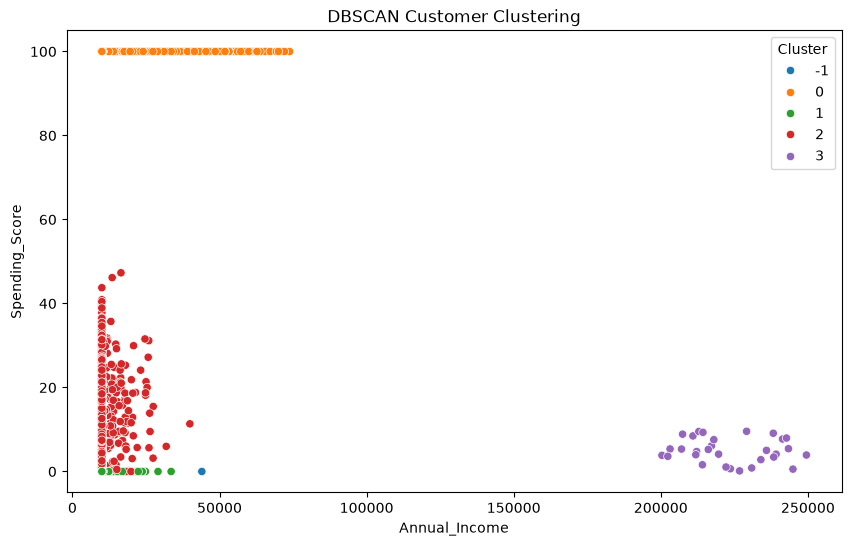

Point_Type
Core      5028
Border       1
Noise        1
Name: count, dtype: int64


,Annual_Income,Spending_Score,Purchases,Website_Visits,Days_Since_Last_Purchase,Cluster,Point_Type
0,10000.000000,100.0,52.974392,20.100125,0.000000,0,Core
1,10000.000000,100.0,60.145085,0.000000,0.000000,0,Core
2,34931.745907,100.0,35.129307,18.759640,0.000000,0,Core
3,10000.000000,0.0,60.330777,20.068879,106.583826,1,Core
4,10000.000000,100.0,49.368815,0.000000,0.000000,0,Core


In [9]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

non_noise_mask = labels != -1

X_clustered = X_scaled[non_noise_mask]
labels_clustered = labels[non_noise_mask]

unique_clusters = np.unique(labels_clustered)

if len(unique_clusters) >= 2:

    sil_score = silhouette_score(
        X_clustered,
        labels_clustered,
        sample_size=min(3000, len(X_clustered)),
        random_state=42
    )

    db_score = davies_bouldin_score(
        X_clustered,
        labels_clustered
    )

    ch_score = calinski_harabasz_score(
        X_clustered,
        labels_clustered
    )

    print("Silhouette Score:", sil_score)
    print("Davies-Bouldin Index:", db_score)
    print("Calinski-Harabasz Score:", ch_score)

else:

    print("Not enough non-noise clusters for these metrics.")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="tab10"
)

plt.title("DBSCAN Customer Clustering")

plt.show()

core_indices = model.core_sample_indices_

core_mask = np.zeros(len(df), dtype=bool)

core_mask[core_indices] = True

df["Point_Type"] = np.where(
    df["Cluster"] == -1,
    "Noise",
    np.where(
        core_mask,
        "Core",
        "Border"
    )
)

print(df["Point_Type"].value_counts())

display(df.head())

## Tune DBSCAN Using a Range of Epsilon Values &  Final DBSCAN Model

In [10]:
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

min_samples_values = [4, 5, 7, 10]

results = []

for eps_value in eps_values:

    for min_samples_value in min_samples_values:

        model = DBSCAN(
            eps=eps_value,
            min_samples=min_samples_value
        )

        labels = model.fit_predict(X_scaled)

        cluster_labels = set(labels) - {-1}

        number_clusters = len(cluster_labels)

        noise_count = np.sum(labels == -1)

        noise_percentage = (
            noise_count / len(labels)
        ) * 100

        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan

        non_noise = labels != -1

        if (
            number_clusters >= 2
            and np.sum(non_noise) > number_clusters
        ):

            X_valid = X_scaled[non_noise]
            labels_valid = labels[non_noise]

            silhouette = silhouette_score(
                X_valid,
                labels_valid,
                sample_size=min(2000, len(X_valid)),
                random_state=42
            )

            davies_bouldin = davies_bouldin_score(
                X_valid,
                labels_valid
            )

            calinski_harabasz = calinski_harabasz_score(
                X_valid,
                labels_valid
            )

        results.append({
            "eps": eps_value,
            "min_samples": min_samples_value,
            "Number_of_Clusters": number_clusters,
            "Noise_Percentage": noise_percentage,
            "Silhouette": silhouette,
            "Davies_Bouldin": davies_bouldin,
            "Calinski_Harabasz": calinski_harabasz
        })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    "Silhouette",
    ascending=False
))

BEST_EPS = 0.8
BEST_MIN_SAMPLES = 5

final_dbscan = DBSCAN(
    eps=BEST_EPS,
    min_samples=BEST_MIN_SAMPLES
)

final_labels = final_dbscan.fit_predict(X_scaled)

df["Final_Cluster"] = final_labels

print(df["Final_Cluster"].value_counts().sort_index())

    eps  min_samples  Number_of_Clusters  Noise_Percentage  Silhouette  \
3   0.3           10                   4          5.566600    0.729258   
2   0.3            7                   4          3.996024    0.724899   
1   0.3            5                   4          3.419483    0.723621   
7   0.4           10                   4          1.948310    0.720098   
4   0.4            4                   7          0.994036    0.713992   
6   0.4            7                   4          1.749503    0.710270   
5   0.4            5                   7          1.153082    0.709328   
10  0.5            7                   6          0.477137    0.709247   
11  0.5           10                   4          0.934394    0.707828   
15  0.6           10                   5          0.417495    0.707665   
9   0.5            5                   6          0.298211    0.701378   
0   0.3            4                   6          3.081511    0.599512   
13  0.6            5                  

In [11]:
df

,Annual_Income,Spending_Score,Purchases,Website_Visits,Days_Since_Last_Purchase,Cluster,Point_Type,Final_Cluster
0,10000.000000,100.000000,52.974392,20.100125,0.000000,0,Core,0
1,10000.000000,100.000000,60.145085,0.000000,0.000000,0,Core,0
2,34931.745907,100.000000,35.129307,18.759640,0.000000,0,Core,0
3,10000.000000,0.000000,60.330777,20.068879,106.583826,1,Core,1
4,10000.000000,100.000000,49.368815,0.000000,0.000000,0,Core,0
...,...,...,...,...,...,...,...,...
5025,214141.871468,1.601362,1.337314,1.080663,327.628392,3,Core,3
5026,230895.645140,0.840331,4.665382,1.688641,347.743847,3,Core,3
5027,216138.356347,5.243734,2.649321,0.649388,327.248083,3,Core,3
5028,214324.627803,9.329371,2.245164,2.354211,351.477319,3,Core,3


In [12]:
df['Final_Cluster'].value_counts()

Final_Cluster
 0    2500
 1    1250
 2    1249
 3      30
-1       1
Name: count, dtype: int64